# DSA 1101 — Crop Yield Analysis and Prediction

**Group members:**
1. Maxwell Mbondo - 24/06667
2. Mark Kitema - 24/06543
3. Hamdi Mohamed - 24/08115
4. Feisal Noor - 24/07112

**Course:** DSA 1101 ? Principles of Data Science  
**Dataset:** `DSA1101_Practical_Assignments_Datasets.xlsx`, worksheet `A3_Crop_Yield`
**Course:** DSA 1101 — Principles of Data Science  
**Dataset:** `DSA1101_Practical_Assignments_Datasets.xlsx`, worksheet `A3_Crop_Yield`

## Decision problem and analytical questions
This educational analysis explores how recorded rainfall, temperature, fertilizer, farm area, soil, crop and irrigation relate to recorded yield. Intended users are agricultural-support analysts who need an exploratory summary, not farm-input prescriptions. The target is `Yield_tonnes_per_ha`; `Farm_ID` is an identifier and is excluded from predictors.

Questions: (1) How do yield distributions differ across crop, county, soil and irrigation groups? (2) What associations appear between yield and rainfall, fertilizer, temperature and area? (3) How accurately do baseline, linear and tree-based models predict yield on a held-out sample?

**Provenance:** the supplied workbook describes these as simulated teaching data, not observations from real farms. Real-world use would require a clear purpose, informed participation, data minimization, access controls, secure storage and a review of ownership and applicable law.

In [1]:
from pathlib import Path
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from scipy.stats import mannwhitneyu
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

SEED = 42
DATA_FILE = Path("DSA1101_Practical_Assignments_Datasets.xlsx")
OUT = Path("outputs")
FIG = OUT / "figures"
OUT.mkdir(exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
print({
    "Python": platform.python_version(),
    "pandas": pd.__version__,
    "NumPy": np.__version__,
    "Matplotlib": plt.matplotlib.__version__,
    "Seaborn": sns.__version__,
    "scikit-learn": sklearn.__version__,
})
if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Place {DATA_FILE.name} beside this notebook before running."
    )
raw = pd.read_excel(DATA_FILE, sheet_name="A3_Crop_Yield")
print("Raw shape:", raw.shape)
display(raw.head(), raw.dtypes.rename("dtype").to_frame(),
        raw.describe(include="all").T)

{'Python': '3.13.14', 'pandas': '3.1.1', 'NumPy': '2.5.4', 'Matplotlib': '3.11.2', 'Seaborn': '0.13.2', 'scikit-learn': '1.9.1'}


Raw shape: (201, 10)


,Farm_ID,County,Crop_Type,Farm_Area_Ha,Annual_Rainfall_mm,Mean_Temperature_C,Fertilizer_kg_per_ha,Soil_Type,Irrigation,Yield_tonnes_per_ha
0,FARM001,Meru,Maize,6.89,963.0,23.4,80.3,Sandy,Yes,2.35
1,FARM002,Uasin Gishu,Maize,5.66,554.2,17.2,63.0,Loam,No,3.36
2,FARM003,Nakuru,Maize,6.35,911.6,24.9,76.1,Clay,No,3.90
3,FARM004,Trans Nzoia,Beans,0.89,642.6,20.1,123.3,Sandy,No,1.85
4,FARM005,Uasin Gishu,Beans,2.99,524.2,23.2,124.3,Loam,Yes,1.62


,dtype
Farm_ID,str
County,str
Crop_Type,str
Farm_Area_Ha,float64
Annual_Rainfall_mm,float64
Mean_Temperature_C,float64
Fertilizer_kg_per_ha,float64
Soil_Type,str
Irrigation,str
Yield_tonnes_per_ha,float64


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Farm_ID,201,200,FARM032,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
County,201,6,Meru,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Crop_Type,201,4,Maize,88,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Farm_Area_Ha,201.0,NaN,NaN,NaN,3.905323,2.325072,0.0,2.25,3.22,5.25,15.0
Annual_Rainfall_mm,196.0,NaN,NaN,NaN,722.468367,218.212253,250.0,590.975,724.6,827.05,2500.0
Mean_Temperature_C,201.0,NaN,NaN,NaN,23.111443,3.728823,14.0,20.2,23.0,25.5,32.0
Fertilizer_kg_per_ha,196.0,NaN,NaN,NaN,96.891327,35.616924,17.1,69.85,93.2,123.675,188.0
Soil_Type,196,4,Loam,76,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Irrigation,201,2,No,150,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Yield_tonnes_per_ha,201.0,NaN,NaN,NaN,4.252537,3.633114,0.2,1.93,3.24,4.35,12.0


## Data dictionary
| Variable | Meaning / unit | Role |
|---|---|---|
| `Farm_ID` | Synthetic farm identifier | ID only; excluded |
| `County` | County label | Categorical predictor |
| `Crop_Type` | Recorded crop type | Categorical predictor |
| `Farm_Area_Ha` | Farm area in hectares (ha) | Numeric predictor |
| `Annual_Rainfall_mm` | Annual rainfall in millimetres (mm) | Numeric predictor |
| `Mean_Temperature_C` | Mean temperature in degrees Celsius (°C) | Numeric predictor |
| `Fertilizer_kg_per_ha` | Fertilizer application in kg/ha | Numeric predictor |
| `Soil_Type` | Recorded soil category | Categorical predictor |
| `Irrigation` | Recorded irrigation status | Categorical predictor |
| `Yield_tonnes_per_ha` | Yield in tonnes per hectare | Target |

## Quality rules and decisions
Drop the repeated `Farm_ID` record after confirming the repeated row is identical. A zero farm area is invalid for a farm-level yield record; set it missing and retain the record, imputing only inside training pipelines. Preserve missing rainfall/fertilizer and label missing soil as `Unknown`; report a complete-case comparison and let pipeline imputers fit on training data. Flag rainfall above 2,000 mm as requiring source verification but retain it because the workbook gives no provenance that establishes it as impossible. Do not remove high yields simply for being unusual.

In [2]:
crop = raw.copy()
numeric_cols = [
    "Farm_Area_Ha", "Annual_Rainfall_mm", "Mean_Temperature_C",
    "Fertilizer_kg_per_ha", "Yield_tonnes_per_ha",
]
for col in numeric_cols:
    crop[col] = pd.to_numeric(crop[col], errors="coerce")

audit = [{
    "issue": "Exact duplicate rows",
    "count": int(crop.duplicated().sum()),
    "decision": "Drop repeated exact record; retain first occurrence.",
}, {
    "issue": "Duplicate farm IDs",
    "count": int(crop["Farm_ID"].duplicated().sum()),
    "decision": "Keep first row after confirming duplicated farm record is identical.",
}]
quality_events = []
duplicate_rows = crop.loc[crop.duplicated(subset="Farm_ID", keep="first")]
for _, row in duplicate_rows.iterrows():
    quality_events.append({
        "record_id": row["Farm_ID"],
        "issue": "Duplicate Farm_ID",
        "original_value": "Repeated exact row",
        "action": "Removed repeated row; retained first occurrence.",
    })
crop = crop.drop_duplicates(subset="Farm_ID", keep="first").copy()
for col in numeric_cols + ["Soil_Type"]:
    missing = int(crop[col].isna().sum())
    for record_id in crop.loc[crop[col].isna(), "Farm_ID"]:
        quality_events.append({
            "record_id": record_id,
            "issue": f"Missing {col}",
            "original_value": "",
            "action": (
                "Retained as missing; numeric values are imputed inside training pipeline."
                if col in numeric_cols else
                "Retained row and label category Unknown."
            ),
        })
    audit.append({
        "issue": f"Missing {col}", "count": missing,
        "decision": (
            "Preserve as missing; numeric median imputation is fitted inside training CV/model pipeline."
            if col in numeric_cols else
            "Preserve row and use explicit Unknown category in the analysis/model."
        ),
    })
zero_area = crop["Farm_Area_Ha"].le(0)
for record_id in crop.loc[zero_area, "Farm_ID"]:
    quality_events.append({
        "record_id": record_id,
        "issue": "Farm_Area_Ha <= 0",
        "original_value": "0",
        "action": "Set area to missing; row retained and model imputes within training folds.",
    })
audit.append({
    "issue": "Farm area <= 0",
    "count": int(zero_area.sum()),
    "decision": "Set to missing and retain; median-impute inside training pipeline only.",
})
crop.loc[zero_area, "Farm_Area_Ha"] = np.nan
high_rain = crop["Annual_Rainfall_mm"].gt(2000)
for _, row in crop.loc[high_rain].iterrows():
    quality_events.append({
        "record_id": row["Farm_ID"],
        "issue": "Annual_Rainfall_mm > 2,000",
        "original_value": f"{row['Annual_Rainfall_mm']:.1f} mm",
        "action": "Retained and flagged; verify against source records.",
    })
yield_q1, yield_q3 = crop["Yield_tonnes_per_ha"].quantile([0.25, 0.75])
yield_upper_fence = yield_q3 + 1.5 * (yield_q3 - yield_q1)
high_yield = crop["Yield_tonnes_per_ha"].gt(yield_upper_fence)
for _, row in crop.loc[high_yield].iterrows():
    quality_events.append({
        "record_id": row["Farm_ID"],
        "issue": "Yield above 1.5×IQR review fence",
        "original_value": f"{row['Yield_tonnes_per_ha']:.2f} tonnes/ha",
        "action": "Retained; investigate measurement and crop context before real-world use.",
    })
audit.append({
    "issue": "Rainfall > 2,000 mm",
    "count": int(high_rain.sum()),
    "decision": "Flag for source verification; retain because plausibility cannot be resolved from workbook.",
})
crop["Rainfall_Review_Flag"] = high_rain
crop["Yield_Review_Flag"] = high_yield
audit.append({
    "issue": "Yield above 1.5×IQR review fence",
    "count": int(high_yield.sum()),
    "decision": "Flag for contextual review; retain unusual observations.",
})
crop["Soil_Type"] = crop["Soil_Type"].fillna("Unknown")
audit_df = pd.DataFrame(audit)
quality_log = pd.DataFrame(quality_events)
display(audit_df)
display(quality_log.head(10))
crop.to_csv(OUT / "A3_Crop_Yield_cleaned.csv", index=False)
audit_df.to_csv(OUT / "A3_Crop_Yield_quality_summary.csv", index=False)
quality_log.to_csv(OUT / "A3_Crop_Yield_quality_log.csv", index=False)
print("Clean data shape:", crop.shape)
print("Farm ID duplicates remaining:", crop["Farm_ID"].duplicated().sum())

numeric_summary = crop[numeric_cols].agg(
    ["count", "mean", "median", "std", "min", "max"]
).T
numeric_summary["Q1"] = crop[numeric_cols].quantile(0.25)
numeric_summary["Q3"] = crop[numeric_cols].quantile(0.75)
display(numeric_summary)
numeric_summary.to_csv(OUT / "A3_Crop_Yield_numeric_summary.csv")

candidate = crop.drop(columns=["Farm_ID"])
complete_rows = candidate.dropna(subset=numeric_cols + ["Soil_Type"]).shape[0]
imputed_cells = int(crop[numeric_cols + ["Soil_Type"]].isna().sum().sum())
print({
    "Rows after deduplication": len(crop),
    "Complete cases across analysis fields": complete_rows,
    "Rows retained with training-only pipeline imputation": len(crop),
    "Missing cells before model imputation": imputed_cells,
    "Missing-data decision": (
        "Prefer retaining eligible records and using training-fitted median/constant imputers; "
        "complete-case analysis is shown as a sensitivity count, not the primary model."
    ),
})

,issue,count,decision
0,Exact duplicate rows,1,Drop repeated exact record; retain first occur...
1,Duplicate farm IDs,1,Keep first row after confirming duplicated far...
2,Missing Farm_Area_Ha,0,Preserve as missing; numeric median imputation...
3,Missing Annual_Rainfall_mm,5,Preserve as missing; numeric median imputation...
4,Missing Mean_Temperature_C,0,Preserve as missing; numeric median imputation...
5,Missing Fertilizer_kg_per_ha,5,Preserve as missing; numeric median imputation...
6,Missing Yield_tonnes_per_ha,0,Preserve as missing; numeric median imputation...
7,Missing Soil_Type,4,Preserve row and use explicit Unknown category...
8,Farm area <= 0,1,Set to missing and retain; median-impute insid...
9,"Rainfall > 2,000 mm",1,Flag for source verification; retain because p...


,record_id,issue,original_value,action
0,FARM032,Duplicate Farm_ID,Repeated exact row,Removed repeated row; retained first occurrence.
1,FARM010,Missing Annual_Rainfall_mm,,Retained as missing; numeric values are impute...
2,FARM040,Missing Annual_Rainfall_mm,,Retained as missing; numeric values are impute...
3,FARM054,Missing Annual_Rainfall_mm,,Retained as missing; numeric values are impute...
4,FARM141,Missing Annual_Rainfall_mm,,Retained as missing; numeric values are impute...
5,FARM180,Missing Annual_Rainfall_mm,,Retained as missing; numeric values are impute...
6,FARM013,Missing Fertilizer_kg_per_ha,,Retained as missing; numeric values are impute...
7,FARM077,Missing Fertilizer_kg_per_ha,,Retained as missing; numeric values are impute...
8,FARM099,Missing Fertilizer_kg_per_ha,,Retained as missing; numeric values are impute...
9,FARM126,Missing Fertilizer_kg_per_ha,,Retained as missing; numeric values are impute...


Clean data shape: (200, 12)
Farm ID duplicates remaining: 0


,count,mean,median,std,min,max,Q1,Q3
Farm_Area_Ha,199.0,3.937437,3.240,2.313289,0.66,15.0,2.2800,5.2550
Annual_Rainfall_mm,195.0,721.926667,724.500,218.641768,250.00,2500.0,590.5500,826.5500
Mean_Temperature_C,200.0,23.086500,22.950,3.721332,14.00,32.0,20.1750,25.4250
Fertilizer_kg_per_ha,195.0,96.648718,93.200,35.545865,17.10,188.0,69.8000,123.6000
Yield_tonnes_per_ha,200.0,4.213800,3.235,3.600377,0.20,12.0,1.9275,4.3425


{'Rows after deduplication': 200, 'Complete cases across analysis fields': 189, 'Rows retained with training-only pipeline imputation': 200, 'Missing cells before model imputation': 11, 'Missing-data decision': 'Prefer retaining eligible records and using training-fitted median/constant imputers; complete-case analysis is shown as a sensitivity count, not the primary model.'}


## Group comparisons and associations
Group means are presented alongside sample sizes and standard deviations. Scatter plots are exploratory; crop, county, soil, irrigation, farm scale and unmeasured conditions may confound apparent relationships. The bootstrap interval below resamples observed cleaned records and is not a population guarantee.

In [3]:
group_tables = {}
for col in ["Crop_Type", "County", "Soil_Type", "Irrigation"]:
    table = crop.groupby(col, dropna=False)["Yield_tonnes_per_ha"].agg(
        n="count", mean="mean", median="median", std="std"
    ).sort_values("mean", ascending=False)
    group_tables[col] = table
    print(f"Yield by {col}")
    display(table.round(3))
    table.to_csv(OUT / f"A3_Crop_Yield_by_{col}.csv")

relationships = [
    "Farm_Area_Ha", "Annual_Rainfall_mm", "Mean_Temperature_C",
    "Fertilizer_kg_per_ha", "Yield_tonnes_per_ha",
]
corr = crop[relationships].corr(method="spearman")
display(corr.round(3))
corr.to_csv(OUT / "A3_Crop_Yield_spearman_correlations.csv")

rng = np.random.default_rng(SEED)
yields = crop["Yield_tonnes_per_ha"].dropna().to_numpy()
boot_means = np.mean(
    rng.choice(yields, size=(5000, len(yields)), replace=True), axis=1
)
ci_low, ci_high = np.quantile(boot_means, [0.025, 0.975])
print(f"Bootstrap 95% percentile CI for mean yield: {ci_low:.3f}–{ci_high:.3f} tonnes/ha")

irrigation_groups = [
    crop.loc[crop["Irrigation"].eq(label), "Yield_tonnes_per_ha"].dropna()
    for label in ["Yes", "No"]
]
test = mannwhitneyu(irrigation_groups[0], irrigation_groups[1], alternative="two-sided")
print({
    "Irrigation Yes n": len(irrigation_groups[0]),
    "Irrigation Yes median": irrigation_groups[0].median(),
    "Irrigation No n": len(irrigation_groups[1]),
    "Irrigation No median": irrigation_groups[1].median(),
    "Mann–Whitney U": test.statistic,
    "p-value": test.pvalue,
    "Interpretation": (
        "A distributional association test only; groups are not randomized and this is not a causal effect."
    ),
})

Yield by Crop_Type


,n,mean,median,std
Crop_Type,,,,
Potatoes,32,12.000,12.000,0.000
Rice,25,3.738,3.820,0.838
Maize,88,3.162,3.265,1.015
Beans,55,1.583,1.510,0.957


Yield by County


,n,mean,median,std
County,,,,
Trans Nzoia,32,4.617,3.235,3.793
Meru,38,4.576,3.305,3.738
Bungoma,37,4.424,3.270,3.901
Uasin Gishu,35,4.192,3.160,3.851
Kirinyaga,32,3.800,3.090,3.362
Nakuru,26,3.428,3.065,2.689


Yield by Soil_Type


,n,mean,median,std
Soil_Type,,,,
Unknown,4,5.068,3.61,5.038
Silty,28,4.813,3.35,3.973
Clay,45,4.729,3.35,3.847
Loam,76,4.040,3.08,3.495
Sandy,47,3.572,3.03,3.175


Yield by Irrigation


,n,mean,median,std
Irrigation,,,,
Yes,51,4.480,3.53,3.224
No,149,4.123,3.15,3.726


,Farm_Area_Ha,Annual_Rainfall_mm,Mean_Temperature_C,Fertilizer_kg_per_ha,Yield_tonnes_per_ha
Farm_Area_Ha,1.000,0.007,0.038,0.055,0.008
Annual_Rainfall_mm,0.007,1.000,0.047,0.019,0.296
Mean_Temperature_C,0.038,0.047,1.000,0.138,0.019
Fertilizer_kg_per_ha,0.055,0.019,0.138,1.000,0.157
Yield_tonnes_per_ha,0.008,0.296,0.019,0.157,1.000


Bootstrap 95% percentile CI for mean yield: 3.717–4.723 tonnes/ha
{'Irrigation Yes n': 51, 'Irrigation Yes median': np.float64(3.53), 'Irrigation No n': 149, 'Irrigation No median': np.float64(3.15), 'Mann–Whitney U': np.float64(4545.5), 'p-value': np.float64(0.0362648452059861), 'Interpretation': 'A distributional association test only; groups are not randomized and this is not a causal effect.'}


## Visualizations
All figures are saved under `outputs/figures/`. Group sample sizes are shown in the group summary tables above.

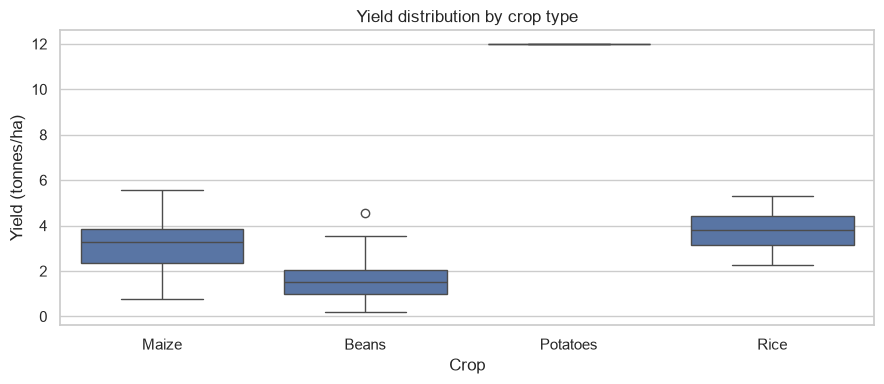

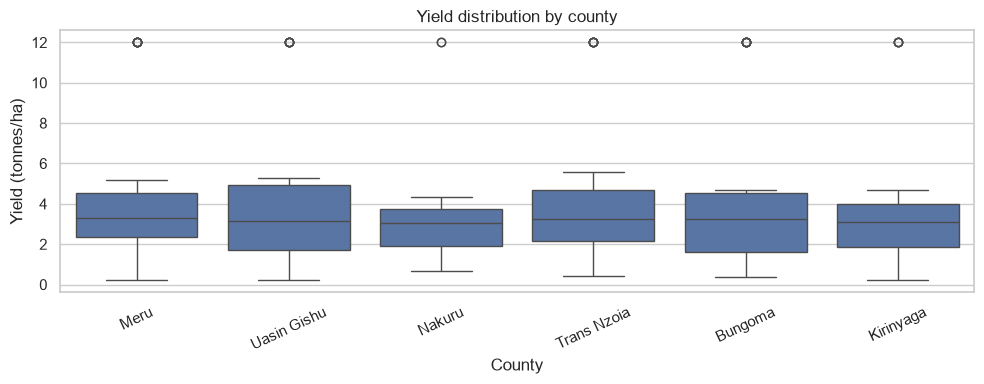

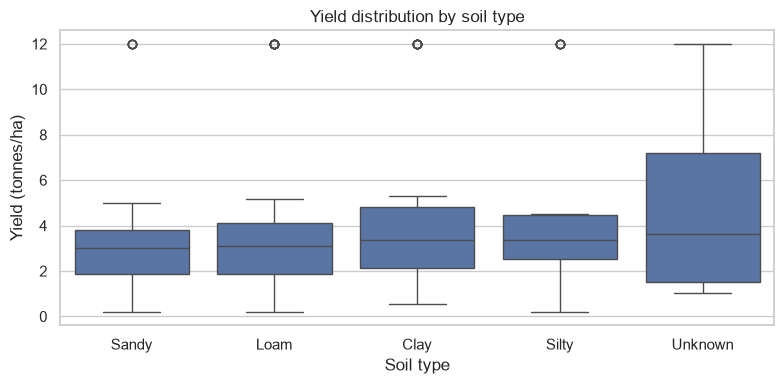

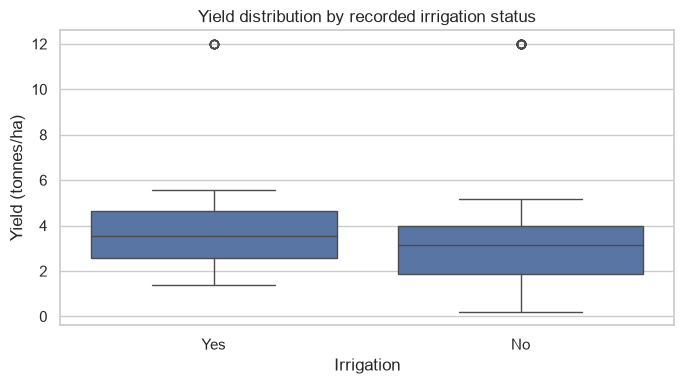

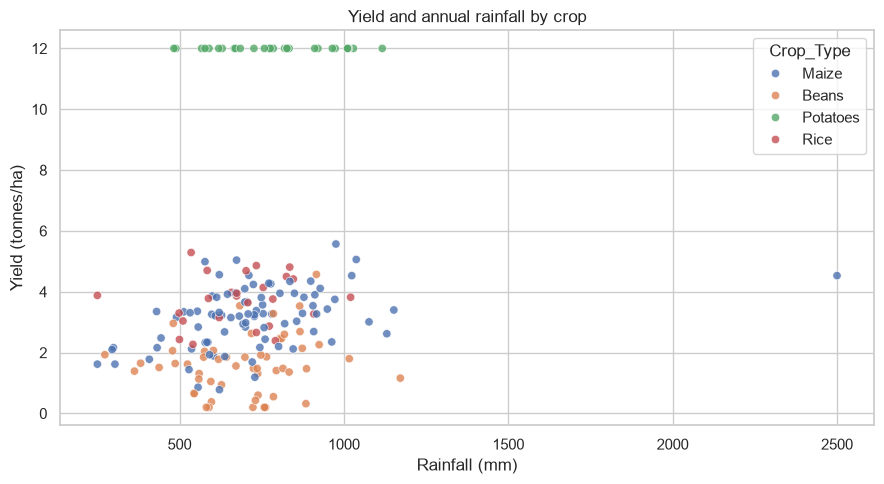

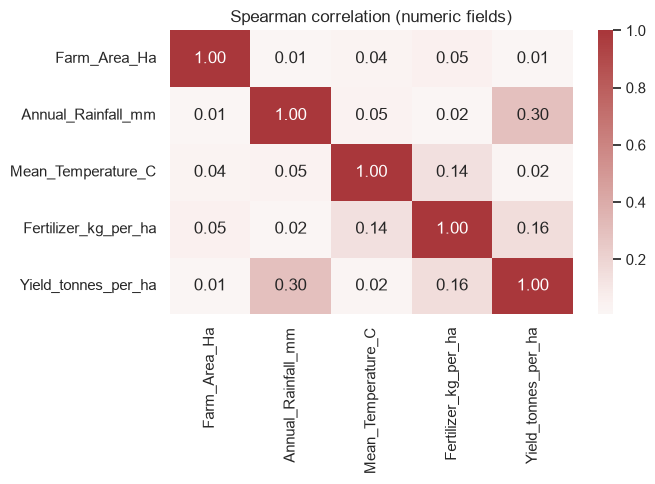

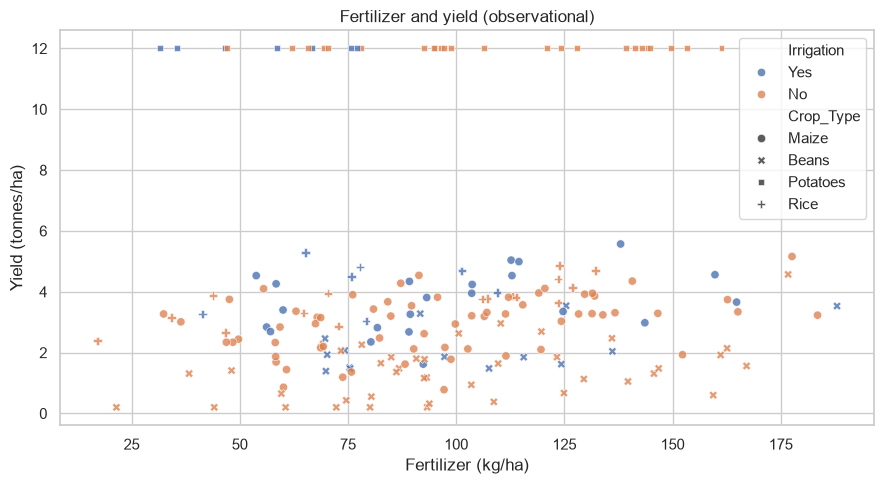

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=crop, x="Crop_Type", y="Yield_tonnes_per_ha", ax=ax)
ax.set(title="Yield distribution by crop type", xlabel="Crop", ylabel="Yield (tonnes/ha)")
fig.tight_layout(); fig.savefig(FIG / "A3_01_yield_by_crop.png", dpi=160); plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=crop, x="County", y="Yield_tonnes_per_ha", ax=ax)
ax.tick_params(axis="x", rotation=25)
ax.set(title="Yield distribution by county", xlabel="County", ylabel="Yield (tonnes/ha)")
fig.tight_layout(); fig.savefig(FIG / "A3_02_yield_by_county.png", dpi=160); plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=crop, x="Soil_Type", y="Yield_tonnes_per_ha", ax=ax)
ax.set(title="Yield distribution by soil type", xlabel="Soil type", ylabel="Yield (tonnes/ha)")
fig.tight_layout(); fig.savefig(FIG / "A3_03_yield_by_soil.png", dpi=160); plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=crop, x="Irrigation", y="Yield_tonnes_per_ha", ax=ax)
ax.set(title="Yield distribution by recorded irrigation status",
       xlabel="Irrigation", ylabel="Yield (tonnes/ha)")
fig.tight_layout(); fig.savefig(FIG / "A3_04_yield_by_irrigation.png", dpi=160); plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=crop, x="Annual_Rainfall_mm", y="Yield_tonnes_per_ha",
                hue="Crop_Type", alpha=.8, ax=ax)
ax.set(title="Yield and annual rainfall by crop", xlabel="Rainfall (mm)",
       ylabel="Yield (tonnes/ha)")
fig.tight_layout(); fig.savefig(FIG / "A3_05_rainfall_yield.png", dpi=160); plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set(title="Spearman correlation (numeric fields)")
fig.tight_layout(); fig.savefig(FIG / "A3_06_correlation_heatmap.png", dpi=160); plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=crop, x="Fertilizer_kg_per_ha", y="Yield_tonnes_per_ha",
                hue="Irrigation", style="Crop_Type", alpha=.8, ax=ax)
ax.set(title="Fertilizer and yield (observational)", xlabel="Fertilizer (kg/ha)",
       ylabel="Yield (tonnes/ha)")
fig.tight_layout(); fig.savefig(FIG / "A3_07_fertilizer_yield.png", dpi=160); plt.show()

## Yield prediction and evaluation
All models use the same fixed 80:20 random split. A random split is suitable for a basic exercise but can overstate generalization if farms from the same county or related sampling process appear in both sets. A stricter follow-up would hold out entire counties or farms. Imputation and one-hot encoding are kept inside scikit-learn pipelines, so they are fitted only on the relevant training fold.

,Model,CV MAE (tonnes/ha),CV RMSE (tonnes/ha),Test MAE (tonnes/ha),Test RMSE (tonnes/ha),Test R-squared
0,Training mean baseline,NaN,NaN,2.390,3.589,-0.021
1,Linear regression,0.644,0.817,0.678,0.823,0.946
2,Random forest,0.631,0.857,0.606,0.829,0.946


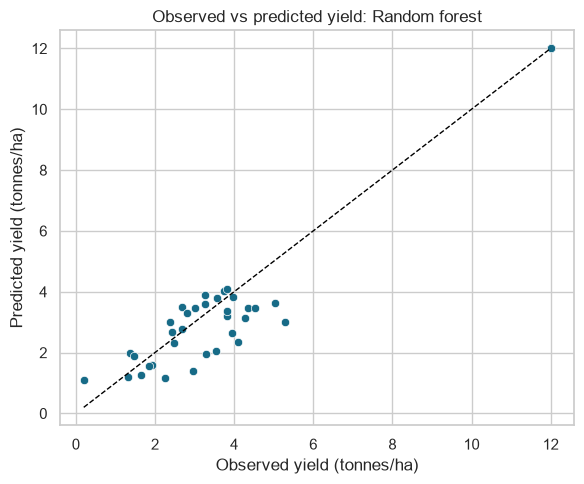

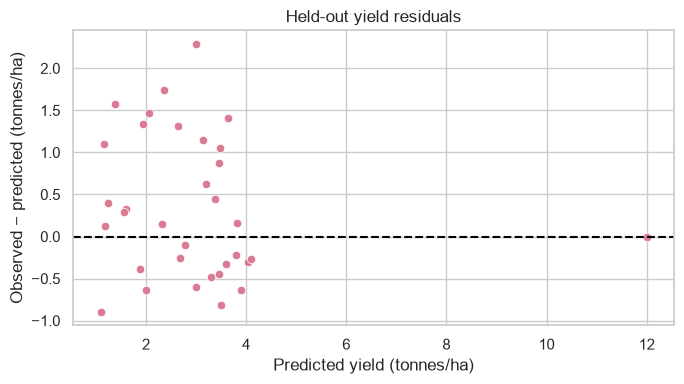

,n,MAE
Crop_Type,,
Beans,12,0.724
Maize,14,0.737
Potatoes,7,0.000
Rice,7,0.746


Selected for descriptive held-out comparison only: Random forest


In [5]:
target = "Yield_tonnes_per_ha"
numeric_features = [
    "Farm_Area_Ha", "Annual_Rainfall_mm", "Mean_Temperature_C",
    "Fertilizer_kg_per_ha",
]
categorical_features = ["County", "Crop_Type", "Soil_Type", "Irrigation"]
features = numeric_features + categorical_features
modeling = crop.dropna(subset=[target]).copy()
X = modeling[features]
y = modeling[target]
X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X, y, modeling.index, test_size=0.20, random_state=SEED
)
preprocess = ColumnTransformer([
    ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median"))]),
     numeric_features),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), categorical_features),
])
models = {
    "Training mean baseline": DummyRegressor(strategy="mean"),
    "Linear regression": Pipeline([
        ("preprocess", preprocess), ("model", LinearRegression())
    ]),
    "Random forest": Pipeline([
        ("preprocess", preprocess),
        ("model", RandomForestRegressor(
            n_estimators=400, min_samples_leaf=3, random_state=SEED
        )),
    ]),
}
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []
fitted = {}
for name, model in models.items():
    if name == "Training mean baseline":
        cv_mae, cv_rmse = np.nan, np.nan
    else:
        cv_result = cross_validate(
            model, X_train, y_train, cv=cv,
            scoring={"mae": "neg_mean_absolute_error",
                     "rmse": "neg_root_mean_squared_error",
                     "r2": "r2"},
            return_train_score=False,
        )
        cv_mae = -cv_result["test_mae"].mean()
        cv_rmse = -cv_result["test_rmse"].mean()
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    fitted[name] = (model, pred)
    rows.append({
        "Model": name,
        "CV MAE (tonnes/ha)": cv_mae,
        "CV RMSE (tonnes/ha)": cv_rmse,
        "Test MAE (tonnes/ha)": mean_absolute_error(y_test, pred),
        "Test RMSE (tonnes/ha)": mean_squared_error(y_test, pred) ** 0.5,
        "Test R-squared": r2_score(y_test, pred),
    })
model_results = pd.DataFrame(rows)
display(model_results.round(3))
model_results.to_csv(OUT / "A3_Crop_Yield_model_comparison.csv", index=False)
best_name = model_results.loc[
    model_results["Test MAE (tonnes/ha)"].idxmin(), "Model"
]
best_model, best_pred = fitted[best_name]
residuals = y_test.to_numpy() - best_pred

fig, ax = plt.subplots(figsize=(6, 5))
sns.scatterplot(x=y_test, y=best_pred, ax=ax, color="#176B87")
limits = [min(y_test.min(), best_pred.min()), max(y_test.max(), best_pred.max())]
ax.plot(limits, limits, "--", color="black", linewidth=1)
ax.set(title=f"Observed vs predicted yield: {best_name}",
       xlabel="Observed yield (tonnes/ha)", ylabel="Predicted yield (tonnes/ha)")
fig.tight_layout(); fig.savefig(FIG / "A3_08_observed_predicted.png", dpi=160); plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(x=best_pred, y=residuals, ax=ax, color="#DA7B93")
ax.axhline(0, color="black", linestyle="--")
ax.set(title="Held-out yield residuals", xlabel="Predicted yield (tonnes/ha)",
       ylabel="Observed − predicted (tonnes/ha)")
fig.tight_layout(); fig.savefig(FIG / "A3_09_residuals.png", dpi=160); plt.show()

error_by_crop = pd.DataFrame({
    "Crop_Type": modeling.loc[idx_test, "Crop_Type"].to_numpy(),
    "Observed": y_test.to_numpy(),
    "Predicted": best_pred,
})
error_by_crop["Absolute_Error"] = (
    error_by_crop["Observed"] - error_by_crop["Predicted"]
).abs()
subgroup = error_by_crop.groupby("Crop_Type").agg(
    n=("Absolute_Error", "size"), MAE=("Absolute_Error", "mean")
)
subgroup = subgroup.loc[subgroup["n"] >= 5]
display(subgroup.round(3))
print("Selected for descriptive held-out comparison only:", best_name)

## Decision-support report and ethics reflection

In [6]:
mean_yield = crop[target].mean()
median_yield = crop[target].median()
crop_means = group_tables["Crop_Type"].sort_values("mean", ascending=False)
high_crop, low_crop = crop_means.index[0], crop_means.index[-1]
high_crop_row, low_crop_row = crop_means.iloc[0], crop_means.iloc[-1]
rainfall_rho = corr.loc["Annual_Rainfall_mm", target]
fertilizer_rho = corr.loc["Fertilizer_kg_per_ha", target]
irrigation_yes = crop.loc[crop["Irrigation"].eq("Yes"), target]
irrigation_no = crop.loc[crop["Irrigation"].eq("No"), target]
irrigation_diff = irrigation_yes.median() - irrigation_no.median()
best_metrics = model_results.loc[model_results["Model"] == best_name].iloc[0]
rain_ids = crop.loc[crop["Rainfall_Review_Flag"], "Farm_ID"].tolist()
crop_report = f'''
# Crop-yield decision support (one-page summary)

**Question and data.** Explore yield patterns and assess basic prediction on the synthetic `A3_Crop_Yield` worksheet. Target: yield (tonnes/ha); predictors: area, rainfall, temperature, fertilizer, county, crop, soil and irrigation. `Farm_ID` is excluded. After dropping the repeated exact farm record, {len(crop)} records remain. Missing numeric values are retained and imputed by training-fitted medians; missing soil is labeled Unknown. One zero farm area is set missing. Rainfall values above 2,000 mm are flagged for verification and kept.

**Three findings.** (1) Mean yield is {mean_yield:.2f} and median yield {median_yield:.2f} tonnes/ha; the bootstrap 95% interval for the sample mean is {ci_low:.2f}–{ci_high:.2f}. (2) {high_crop} has the highest observed crop-group mean ({high_crop_row["mean"]:.2f}, n={int(high_crop_row["n"])}), while {low_crop} is lowest ({low_crop_row["mean"]:.2f}, n={int(low_crop_row["n"])}); groups differ in crop conditions and sample sizes. (3) Spearman correlations are {rainfall_rho:.2f} for rainfall and {fertilizer_rho:.2f} for fertilizer with yield. These are associations, not causal responses. Irrigation-group median difference (Yes minus No) is {irrigation_diff:.2f} tonnes/ha; the Mann–Whitney test p-value is {test.pvalue:.3f}, which does not establish an irrigation effect.

**Model comparison.** On the same held-out split, the best test-MAE model was **{best_name}**: MAE {best_metrics["Test MAE (tonnes/ha)"]:.2f}, RMSE {best_metrics["Test RMSE (tonnes/ha)"]:.2f} tonnes/ha, R-squared {best_metrics["Test R-squared"]:.2f}. See `outputs/A3_Crop_Yield_model_comparison.csv` and the labelled observed-versus-predicted plot. The sample is small; county-level holdout validation is a stronger next test.

**Cautious recommendations.** Use these summaries only to frame questions for local, representative data collection; do not prescribe fertilizer, irrigation or crop changes from these associations. Verify the flagged rainfall and zero-area record against source records and collect contextual information (season, seed variety, management, soil measurements and measurement methods) before any operational use.

## What this analysis cannot establish
These synthetic records cannot establish real Kenyan farm outcomes, representative county rankings, causal effects of inputs or reliable future performance. Missing values, potential sampling bias, repeated patterns, unusual rainfall, omitted agronomic factors and a small sample create uncertainty. Feature importance or a correlation is not evidence that changing an input will raise yield.

## Ethics and limitations reflection
No real farmer is represented in this workbook, but a real deployment could expose sensitive information about land, income, location or agricultural practices. Farmers should understand the purpose and uses of data and participate voluntarily where appropriate. Collect only variables needed for a clearly stated purpose, document ownership and permitted reuse, restrict access by role, encrypt data in transit and at rest and define retention and deletion procedures. Do not assume that a county or crop group is fairly represented merely because it appears in the sample; small farms and under-sampled communities can be hidden by aggregate averages. Explain model limitations in language users can understand and provide a way to challenge inaccurate records or decisions. If personal data are involved, assess obligations under the Kenya Data Protection Act and applicable regulations with qualified guidance. Models trained on observational records can reproduce historical inequities and should not determine access to inputs, credit or support without human review, representative validation and accountability. In this exercise, the simulated provenance, missing contextual variables and random split mean model scores are illustrative only. Any real recommendation should be based on verified local evidence, uncertainty intervals, agronomic expertise and farmer priorities rather than a single score or feature-importance ranking.
'''
(OUT / "A3_Crop_Yield_Decision_Support.md").write_text(
    crop_report.strip() + "\n", encoding="utf-8"
)
print(crop_report)
print("Ethics reflection word count:",
      len(crop_report.split("## Ethics and limitations reflection", 1)[1].split()))


# Crop-yield decision support (one-page summary)

**Question and data.** Explore yield patterns and assess basic prediction on the synthetic `A3_Crop_Yield` worksheet. Target: yield (tonnes/ha); predictors: area, rainfall, temperature, fertilizer, county, crop, soil and irrigation. `Farm_ID` is excluded. After dropping the repeated exact farm record, 200 records remain. Missing numeric values are retained and imputed by training-fitted medians; missing soil is labeled Unknown. One zero farm area is set missing. Rainfall values above 2,000 mm are flagged for verification and kept.

**Three findings.** (1) Mean yield is 4.21 and median yield 3.24 tonnes/ha; the bootstrap 95% interval for the sample mean is 3.72–4.72. (2) Potatoes has the highest observed crop-group mean (12.00, n=32), while Beans is lowest (1.58, n=55); groups differ in crop conditions and sample sizes. (3) Spearman correlations are 0.30 for rainfall and 0.16 for fertilizer with yield. These are associations, not causal

## Reproducibility checklist
- [x] Input file and worksheet named above.
- [x] Python and package versions printed by the first code cell.
- [x] Random seed fixed at 42 for bootstrap, split and forests.
- [x] Cleaning decisions documented; extreme rainfall retained with a review flag.
- [x] Farm ID excluded; preprocessing fit inside model pipelines.
- [x] Training/test split fixed at 80:20; shuffled 5-fold CV on training data.
- [x] Run all cells from a clean kernel with pandas, NumPy, Matplotlib, Seaborn, SciPy, scikit-learn and openpyxl installed.
- [x] Cleaned file, audit, tables, metrics, figures and Markdown report saved under `outputs/`.